# Image inference

Use the PanopTILs model from [training](training.ipynb) to find nuclei and
cell types in a validation image. Each instance label identifies one nucleus;
a class label gives its type. Compare predictions with the dataset labels,
then save the predicted masks.

Complete [data preparation](prepare-data.ipynb) and training first. This example
uses their data and saved model. To use public pretrained weights with your own
image, follow the [quick start](../quickstart.md).


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Patch
from safetensors import safe_open
from skimage.color import label2rgb

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.metrics import panoptic_quality
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.functional.normalization import minmax_normalize
from cellseg_models_pytorch.utils import FileHandler

torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
data_root = Path("../../data/panoptils-nuclei")
checkpoint_path = Path("training-checkpoints/epoch_05/model.safetensors")

# Read the cell-type meanings stored alongside the trained weights.
with safe_open(checkpoint_path, framework="pt", device="cpu") as weights:
    class_names = json.loads(weights.metadata()["class_names"])

model = CellPose.from_pretrained(checkpoint_path, device=device)
model.set_inference_mode(mixed_precision=False)
model.post_processor = PostProcessor("cellpose", {"use_gpu": device.type == "cuda"})

# Keep the validation image at its original size.
image_path = sorted((data_root / "validation/regions/images").glob("*.png"))[0]
raw_image = FileHandler.read_img(image_path)
labels = FileHandler.read_mat(data_root / "validation/regions/labels" / f"{image_path.stem}.mat")
image = minmax_normalize(raw_image, copy=True)


Device: cuda


In [2]:
# Separate nuclei and assign one cell type to each nucleus.
prediction = model.predict(image)
result = model.post_process(prediction, use_async_postproc=False)
instances, classes = result["nuc"][0]

print("Predicted nuclei:", len(np.unique(instances[instances > 0])))
print("Instance PQ:", round(panoptic_quality(labels["inst"], instances)["pq"], 3))


Predicted nuclei: 623


Instance PQ: 0.686


## Compare the masks

Compare the same tissue image with its labels and predictions. Panoptic quality
(PQ) measures nucleus matching and overlap; 1 is perfect. This score describes one
image. The training example checks 16 validation images.

The legend identifies tumour (neoplastic), supporting tissue (stromal) and immune
(inflammatory) cells. “Unknown” means the dataset did not assign a specific type.
Brown nuclei were assigned class 0; black is background with no nucleus.


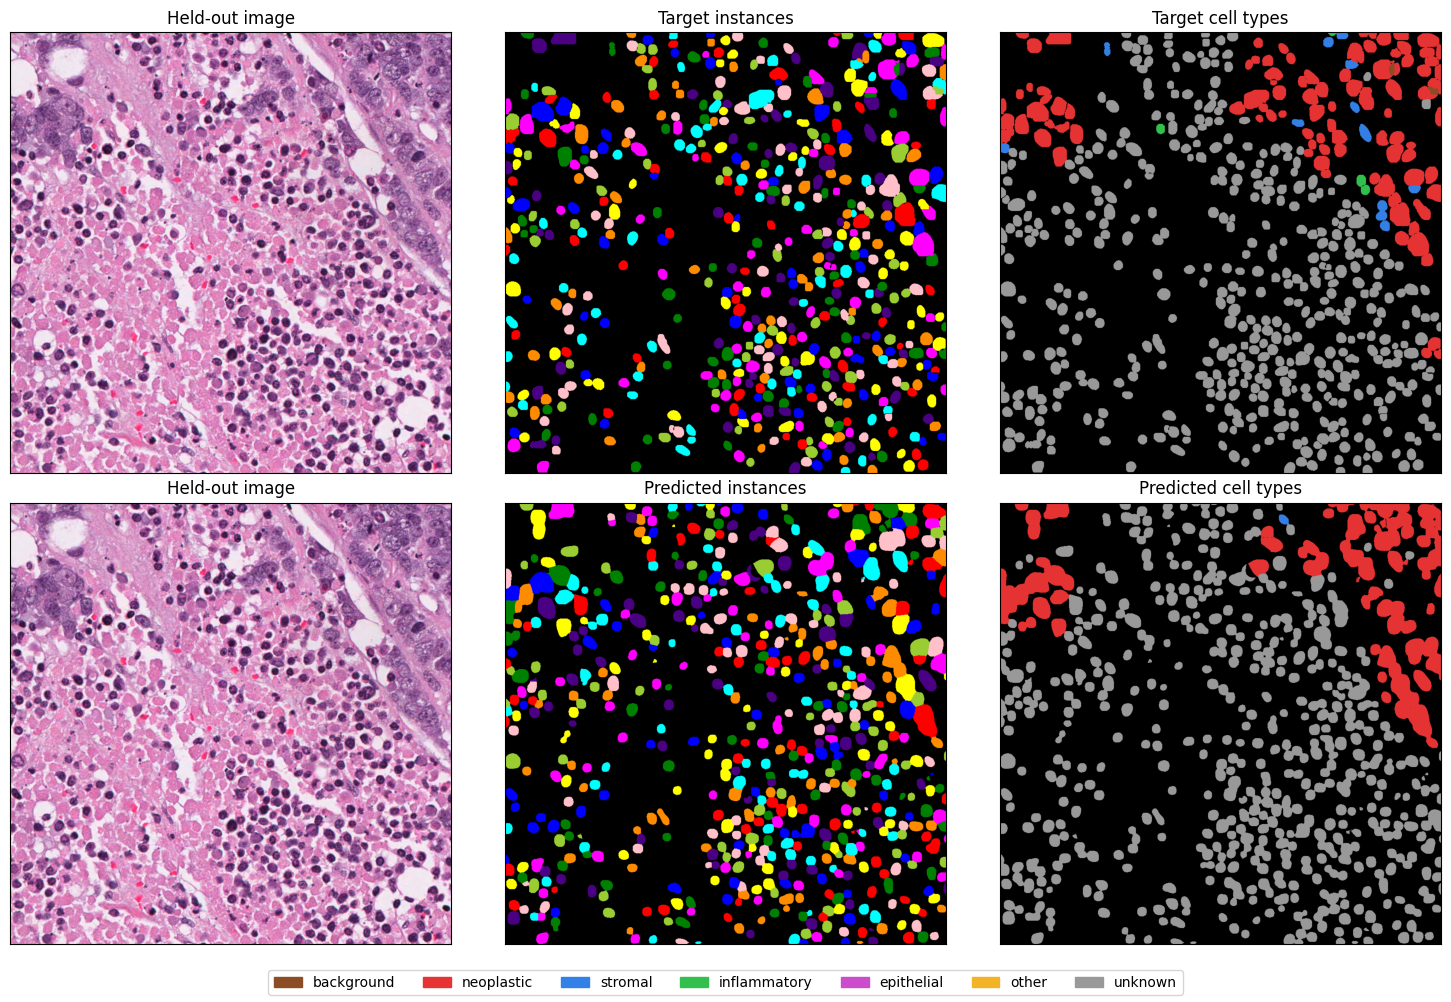

In [3]:
class_palette = np.array([
    [0.55, 0.3, 0.15], [0.9, 0.2, 0.2], [0.2, 0.5, 0.9], [0.2, 0.75, 0.3],
    [0.8, 0.3, 0.8], [0.95, 0.7, 0.15], [0.6, 0.6, 0.6],
])
instance_colors = label2rgb(instances, bg_label=0)
class_colors = class_palette[classes]
class_colors[instances == 0] = 0

target_class_colors = class_palette[labels["type"].astype(int)]
target_class_colors[labels["inst"] == 0] = 0

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(raw_image)
axes[0, 0].set_title("Held-out image")
axes[0, 1].imshow(label2rgb(labels["inst"], bg_label=0))
axes[0, 1].set_title("Target instances")
axes[0, 2].imshow(target_class_colors)
axes[0, 2].set_title("Target cell types")
axes[1, 0].imshow(raw_image)
axes[1, 0].set_title("Held-out image")
axes[1, 1].imshow(instance_colors)
axes[1, 1].set_title("Predicted instances")
axes[1, 2].imshow(class_colors)
axes[1, 2].set_title("Predicted cell types")
for axis in axes.flat:
    axis.set(xticks=[], yticks=[])
fig.legend([Patch(color=colour) for colour in class_palette], class_names,
           loc="lower center", ncol=7)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


## Save the masks

Set `output_path`, then uncomment the save block to store both masks in a NumPy
`.npz` file. Integer labels preserve nucleus IDs: zero is background and each
positive number identifies one nucleus. Cell-type IDs keep the meanings shown
in the legend.

For larger images, use overlapping tiles with
`predict(..., use_sliding_win=True, window_size=(256, 256), stride=128)`.
Keep the image at its original resolution so nuclei remain the same size.


In [4]:
output_path = Path("segmentation.npz")
# Choose a filename, then uncomment to save both masks.
# with output_path.open("xb") as output:
#     np.savez_compressed(output, instances=instances, classes=classes)
